# 04 — Repeated Real-Dataset and Controlled Quadratic Experiments

## Purpose

This is the main experimental notebook. It contains three complementary studies:

1. **Real-dataset study:** compare Batch GD, SGD, Momentum, and Adam on Breast Cancer Wisconsin, Banknote Authentication, and Ionosphere.
2. **Cross-dataset replication validation:** apply the same experimental protocol to datasets with different feature spaces, then compare whether scaling effects and optimizer-performance patterns replicate. This is not train-on-one-dataset/test-on-another transfer learning.
3. **Controlled quadratic study:** isolate the effect of Hessian conditioning using a two-dimensional objective with known eigenvalues.

The real-data implementation uses the project's NumPy logistic-regression model and shared optimizer classes. Each dataset receives one fixed, stratified, untouched test holdout. Hyperparameter tuning and repeated model selection use only the remaining development observations.

Run the notebook from top to bottom. The final real-dataset section writes its tables and figures to `results/`; the controlled quadratic experiment follows in Part B.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start=None):
    """Find the repository root from the current Jupyter working directory."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "logistic_regression.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Open Jupyter from the repository "
        "folder or one of its subfolders."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import logistic_regression, optimizers

FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

import time
from itertools import combinations

import seaborn as sns
from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.datasets import load_binary_datasets

## Part A — Repeated experiments on real datasets

### A1. Dataset and experimental configuration

The three datasets are treated as separate experimental environments because their feature dimensions and feature meanings are incompatible. We therefore validate **replication of optimizer and feature-scaling patterns across datasets**, not cross-dataset model transfer.

For each dataset, one stratified 20% test partition is reserved once, before hyperparameter tuning. The same untouched test observations are used for every optimizer, feature condition, and evaluation seed for that dataset. The remaining 80% forms the development pool. Hyperparameter tuning and final early stopping use only development-pool training/validation partitions. Repeated evaluation seeds vary the development-pool train/validation split while keeping the test observations fixed.

The original and standardized conditions use the same row partitions within each seed. Constant-feature removal and standardization are fitted on that run's training partition only.


In [2]:
datasets = load_binary_datasets()
DATASET_NAMES = list(datasets)
CONDITIONS = ["original", "standardized"]
OPTIMIZER_NAMES = ["Adam", "Batch GD", "Momentum", "SGD"]

TUNING_CONFIG = {
    "seed": 42,
    "epochs": 100,
    "validation_fraction_of_development": 0.25,  # 60/20/20 overall
    "l2": 0.0,
}

FINAL_CONFIG = {
    "seeds": list(range(10)),
    "holdout_seed": 2026,
    "test_size": 0.20,
    "validation_fraction_of_development": 0.25,  # 60% train, 20% validation overall
    "max_epochs": 300,
    "patience": 20,
    "min_delta": 1e-6,
    "l2": 0.0,
}


def create_fixed_holdout(X, y, test_size, seed):
    """Reserve one stratified test set; return development/test arrays and row indices."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    all_indices = np.arange(len(y))
    development_indices, test_indices = train_test_split(
        all_indices,
        test_size=test_size,
        random_state=seed,
        stratify=y,
    )
    if np.intersect1d(development_indices, test_indices).size:
        raise AssertionError("Development and test indices overlap.")
    if len(development_indices) + len(test_indices) != len(y):
        raise AssertionError("The fixed holdout does not cover every observation.")
    return {
        "X_development": X[development_indices],
        "y_development": y[development_indices],
        "X_test": X[test_indices],
        "y_test": y[test_indices],
        "development_indices": development_indices,
        "test_indices": test_indices,
    }


# The holdout is created exactly once per dataset and then reused unchanged.
fixed_holdouts = {
    name: create_fixed_holdout(
        X_data, y_data,
        test_size=FINAL_CONFIG["test_size"],
        seed=FINAL_CONFIG["holdout_seed"],
    )
    for name, (X_data, y_data) in datasets.items()
}

holdout_audit_records = []
for name, holdout in fixed_holdouts.items():
    holdout_audit_records.append({
        "Dataset": name,
        "Total Observations": len(holdout["y_development"]) + len(holdout["y_test"]),
        "Development Observations": len(holdout["y_development"]),
        "Fixed Test Observations": len(holdout["y_test"]),
        "Fixed Test Fraction": len(holdout["y_test"]) / (
            len(holdout["y_development"]) + len(holdout["y_test"])
        ),
        "Holdout Seed": FINAL_CONFIG["holdout_seed"],
        "Development/Test Indices Disjoint": not bool(np.intersect1d(
            holdout["development_indices"], holdout["test_indices"]
        ).size),
    })
holdout_audit_df = pd.DataFrame(holdout_audit_records)
assert holdout_audit_df["Development/Test Indices Disjoint"].all()
assert np.allclose(holdout_audit_df["Fixed Test Fraction"], FINAL_CONFIG["test_size"], atol=0.01)

print("Datasets:", DATASET_NAMES)
print("Tuning configuration:", TUNING_CONFIG)
print("Final evaluation configuration:", FINAL_CONFIG)
display(holdout_audit_df)


Datasets: ['Breast Cancer', 'Banknote', 'Ionosphere']
Tuning configuration: {'seed': 42, 'epochs': 100, 'validation_fraction_of_development': 0.25, 'l2': 0.0}
Final evaluation configuration: {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'holdout_seed': 2026, 'test_size': 0.2, 'validation_fraction_of_development': 0.25, 'max_epochs': 300, 'patience': 20, 'min_delta': 1e-06, 'l2': 0.0}


,Dataset,Total Observations,Development Observations,Fixed Test Observations,Fixed Test Fraction,Holdout Seed,Development/Test Indices Disjoint
0,Breast Cancer,569,455,114,0.200351,2026,True
1,Banknote,1372,1097,275,0.200437,2026,True
2,Ionosphere,351,280,71,0.202279,2026,True


### A2. Learning-rate search space and optimizer factory

The optimizer implementations are imported from the shared `src/optimizers.py` module. Batch GD, Momentum, and Adam use full-batch updates in the real-data comparison; SGD uses a batch size of one.

In [3]:
LEARNING_RATE_GRID = {
    "Batch GD": [1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0],
    "SGD": [1e-4, 1e-3, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
    "Momentum": [1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0],
    "Adam": [1e-4, 1e-3, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
}


def create_optimizer(name, learning_rate):
    if name in ("Batch GD", "SGD"):
        return optimizers.GradientDescent(learning_rate=learning_rate)
    if name == "Momentum":
        return optimizers.Momentum(learning_rate=learning_rate, beta=0.9)
    if name == "Adam":
        return optimizers.Adam(learning_rate=learning_rate)
    raise ValueError(f"Unknown optimizer: {name}")


def get_batch_size(name, n_samples):
    return 1 if name == "SGD" else n_samples

### A3. Development-pool splits and preprocessing

The fixed test holdout is created once per dataset before tuning. Within the remaining development pool, each tuning/evaluation seed creates a stratified training/validation split. A validation fraction of 0.25 within the 80% development pool yields approximately 60% training, 20% validation, and 20% test observations overall.

The training partition alone determines the constant-feature mask and, for the standardized condition, the `StandardScaler` parameters. During tuning, the held-out test array is not passed to the preprocessing or training functions. During final evaluation, the already-reserved test observations are transformed with the training-fitted mask/scaler and evaluated only after the best validation epoch has been restored.


In [4]:
def split_development_data(X_development, y_development, seed, validation_fraction):
    """Split only the development pool into stratified train and validation sets."""
    X_train, X_val, y_train, y_val = train_test_split(
        X_development,
        y_development,
        test_size=validation_fraction,
        random_state=seed,
        stratify=y_development,
    )
    return X_train, X_val, y_train, y_val


def prepare_training_validation(
    X_development, y_development, condition, seed, validation_fraction
):
    """Fit feature filtering/scaling on training data; do not access the test holdout."""
    X_train, X_val, y_train, y_val = split_development_data(
        X_development, y_development, seed, validation_fraction
    )

    keep_mask = np.std(X_train, axis=0) > 1e-10
    if not np.any(keep_mask):
        raise ValueError("All features are constant in this training partition.")
    X_train = X_train[:, keep_mask]
    X_val = X_val[:, keep_mask]

    scaler = None
    if condition == "standardized":
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_val = scaler.transform(X_val)
    elif condition != "original":
        raise ValueError("condition must be 'original' or 'standardized'.")

    return {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val,
        "feature_mask": keep_mask,
        "scaler": scaler,
    }


def prepare_evaluation_partition(
    X_development, y_development, X_test_raw, y_test, condition, seed,
    validation_fraction,
):
    """Prepare train/validation data and transform the fixed test set without fitting on it."""
    data = prepare_training_validation(
        X_development,
        y_development,
        condition,
        seed,
        validation_fraction,
    )
    X_test = np.asarray(X_test_raw, dtype=float)[:, data["feature_mask"]]
    if data["scaler"] is not None:
        X_test = data["scaler"].transform(X_test)
    return {
        **data,
        "X_test": X_test,
        "y_test": np.asarray(y_test, dtype=int),
    }


### A4. Validation-based learning-rate tuning

Each learning rate is trained for the same fixed number of epochs. The learning rate with the lowest validation log loss is selected. Candidate rates within a tuning configuration use the same deterministic shuffle seed.

**Leakage protection:** the tuning function receives only the development-pool training and validation arrays. The fixed test holdout is not passed to the tuning function, used for learning-rate selection, or used for early stopping. The tuning seed (42) is separate from the final development-split seeds (0–9).


In [5]:
def tune_optimizer(X_train, y_train, X_val, y_val, optimizer_name, learning_rates):
    records = []
    batch_size = get_batch_size(optimizer_name, len(y_train))

    for learning_rate in learning_rates:
        try:
            model = logistic_regression.LogisticRegression(l2=TUNING_CONFIG["l2"])
            model.fit(
                X_train,
                y_train,
                optimizer=create_optimizer(optimizer_name, learning_rate),
                epochs=TUNING_CONFIG["epochs"],
                batch_size=batch_size,
                shuffle=True,
                random_state=TUNING_CONFIG["seed"],
            )
            probabilities = model.predict_proba(X_val)
            if not np.all(np.isfinite(probabilities)):
                raise FloatingPointError("Non-finite validation probabilities.")
            validation_loss = log_loss(y_val, probabilities, labels=[0, 1])
            if not np.isfinite(validation_loss):
                raise FloatingPointError("Non-finite validation loss.")
            status = "Valid"
        except (FloatingPointError, ValueError, OverflowError):
            validation_loss = np.inf
            status = "Diverged or invalid"

        records.append(
            {
                "Optimizer": optimizer_name,
                "Learning Rate": float(learning_rate),
                "Validation Log Loss": float(validation_loss),
                "Status": status,
            }
        )

    tuning_df = pd.DataFrame(records)
    valid = tuning_df[tuning_df["Status"] == "Valid"]
    if valid.empty:
        raise RuntimeError(f"No valid learning rate found for {optimizer_name}.")
    best = valid.loc[valid["Validation Log Loss"].idxmin()]
    return best, tuning_df


tuning_records = []
selected_hyperparameters = {}

for dataset_name in DATASET_NAMES:
    holdout = fixed_holdouts[dataset_name]
    for condition in CONDITIONS:
        tuning_data = prepare_training_validation(
            holdout["X_development"],
            holdout["y_development"],
            condition,
            seed=TUNING_CONFIG["seed"],
            validation_fraction=TUNING_CONFIG["validation_fraction_of_development"],
        )
        for optimizer_name in OPTIMIZER_NAMES:
            best, candidate_results = tune_optimizer(
                tuning_data["X_train"],
                tuning_data["y_train"],
                tuning_data["X_val"],
                tuning_data["y_val"],
                optimizer_name,
                LEARNING_RATE_GRID[optimizer_name],
            )
            candidate_results["Dataset"] = dataset_name
            candidate_results["Condition"] = condition
            tuning_records.append(candidate_results)
            selected_hyperparameters[(dataset_name, condition, optimizer_name)] = float(
                best["Learning Rate"]
            )
            print(
                f"{dataset_name:14s} | {condition:13s} | {optimizer_name:10s} "
                f"| LR={best['Learning Rate']:.6g} "
                f"| validation log loss={best['Validation Log Loss']:.5f}"
            )

tuning_results_df = pd.concat(tuning_records, ignore_index=True)

selected_rows = []
for (dataset_name, condition, optimizer_name), learning_rate in selected_hyperparameters.items():
    grid = LEARNING_RATE_GRID[optimizer_name]
    at_min = np.isclose(learning_rate, min(grid))
    at_max = np.isclose(learning_rate, max(grid))
    selected_rows.append(
        {
            "Dataset": dataset_name,
            "Condition": condition,
            "Optimizer": optimizer_name,
            "Selected Learning Rate": learning_rate,
            "At Search Boundary": bool(at_min or at_max),
            "Boundary": "Minimum" if at_min else ("Maximum" if at_max else "Interior"),
        }
    )
selected_hyperparameters_df = pd.DataFrame(selected_rows)
display(selected_hyperparameters_df.sort_values(["Dataset", "Condition", "Optimizer"]))

Breast Cancer  | original      | Adam       | LR=0.005 | validation log loss=0.27621
Breast Cancer  | original      | Batch GD   | LR=1e-05 | validation log loss=0.49176
Breast Cancer  | original      | Momentum   | LR=0.0001 | validation log loss=0.32096
Breast Cancer  | original      | SGD        | LR=0.0001 | validation log loss=3.48832
Breast Cancer  | standardized  | Adam       | LR=0.05 | validation log loss=0.07732
Breast Cancer  | standardized  | Batch GD   | LR=2 | validation log loss=0.07535
Breast Cancer  | standardized  | Momentum   | LR=1 | validation log loss=0.07982
Breast Cancer  | standardized  | SGD        | LR=0.01 | validation log loss=0.07290
Banknote       | original      | Adam       | LR=0.2 | validation log loss=0.02507
Banknote       | original      | Batch GD   | LR=2 | validation log loss=0.02680
Banknote       | original      | Momentum   | LR=2 | validation log loss=0.02570
Banknote       | original      | SGD        | LR=0.01 | validation log loss=0.02271

,Dataset,Condition,Optimizer,Selected Learning Rate,At Search Boundary,Boundary
8,Banknote,original,Adam,0.20000,True,Maximum
9,Banknote,original,Batch GD,2.00000,True,Maximum
10,Banknote,original,Momentum,2.00000,True,Maximum
11,Banknote,original,SGD,0.01000,False,Interior
12,Banknote,standardized,Adam,0.20000,True,Maximum
13,Banknote,standardized,Batch GD,2.00000,True,Maximum
14,Banknote,standardized,Momentum,2.00000,True,Maximum
15,Banknote,standardized,SGD,0.20000,True,Maximum
0,Breast Cancer,original,Adam,0.00500,False,Interior
1,Breast Cancer,original,Batch GD,0.00001,True,Minimum


In [6]:
tuning_results_df.to_csv(TABLES_PATH / "hyperparameter_search.csv", index=False)
selected_hyperparameters_df.to_csv(
    TABLES_PATH / "selected_hyperparameters.csv", index=False
)
print("Saved learning-rate search results and selected rates.")

Saved learning-rate search results and selected rates.


### A5. Final repeated evaluation protocol

For each dataset, one stratified 20% test holdout is created once using `holdout_seed=2026`. This exact test set is reused for all feature conditions, optimizers, and ten evaluation seeds. The remaining 80% is the development pool. Each evaluation seed creates a new stratified train/validation split within that development pool, and the selected learning rate is held fixed.

Early stopping monitors validation log loss only. The test set is transformed using preprocessing fitted on the corresponding training partition and is evaluated only after restoring the best validation parameters. No test observation is used for learning-rate selection, feature filtering, scaler fitting, or early stopping.

The design contains (3 datasets) × (2 feature conditions) × (4 optimizers) × (10 development-split seeds) = **240 model runs**. The ten runs for a dataset share the same fixed test observations; they vary the development-pool train/validation split. Consequently, seed-level statistical comparisons describe variability across repeated development splits conditional on the fixed holdout, not ten independent test cohorts.


In [7]:
def train_with_early_stopping(
    X_train, y_train, X_val, y_val, optimizer, batch_size,
    max_epochs, patience, min_delta, l2, seed,
):
    rng = np.random.default_rng(seed)
    X_train_bias = logistic_regression.add_intercept(X_train)
    X_val_bias = logistic_regression.add_intercept(X_val)
    n_samples, n_parameters = X_train_bias.shape

    theta = np.zeros(n_parameters, dtype=float)
    optimizer.reset(n_parameters)
    best_theta = theta.copy()
    best_validation_loss = np.inf
    best_training_loss = np.inf
    best_epoch = 0
    epochs_without_improvement = 0
    training_loss_history = []
    validation_loss_history = []

    for epoch in range(max_epochs):
        indices = rng.permutation(n_samples)
        X_epoch = X_train_bias[indices]
        y_epoch = y_train[indices]

        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            gradient = logistic_regression.compute_gradient(
                X_epoch[start:end], y_epoch[start:end], theta, l2=l2
            )
            theta = optimizer.step(theta, gradient)
            if not np.all(np.isfinite(theta)):
                raise FloatingPointError("Non-finite model parameters encountered.")

        training_loss = logistic_regression.binary_cross_entropy(
            X_train_bias, y_train, theta, l2=l2
        )
        validation_probabilities = logistic_regression.sigmoid(X_val_bias @ theta)
        validation_loss = log_loss(
            y_val, validation_probabilities, labels=[0, 1]
        )
        if not np.isfinite(training_loss) or not np.isfinite(validation_loss):
            raise FloatingPointError("Non-finite loss encountered.")

        training_loss_history.append(training_loss)
        validation_loss_history.append(validation_loss)

        if validation_loss < best_validation_loss - min_delta:
            best_validation_loss = validation_loss
            best_training_loss = training_loss
            best_theta = theta.copy()
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model = logistic_regression.LogisticRegression(l2=l2)
    model.theta = best_theta
    model.n_features_in_ = X_train.shape[1]
    model.loss_history = training_loss_history[:best_epoch]

    return model, {
        "best_epoch": best_epoch,
        "epochs_run": len(training_loss_history),
        "best_validation_loss": best_validation_loss,
        "best_training_loss": best_training_loss,
        "training_loss_history": training_loss_history,
        "validation_loss_history": validation_loss_history,
    }


def run_final_experiments():
    records = []
    expected_runs = (
        len(datasets) * len(CONDITIONS) * len(OPTIMIZER_NAMES) *
        len(FINAL_CONFIG["seeds"])
    )

    for dataset_name in DATASET_NAMES:
        holdout = fixed_holdouts[dataset_name]
        X_development = holdout["X_development"]
        y_development = holdout["y_development"]
        X_test_raw = holdout["X_test"]
        y_test_fixed = holdout["y_test"]

        for condition in CONDITIONS:
            for seed in FINAL_CONFIG["seeds"]:
                data = prepare_evaluation_partition(
                    X_development,
                    y_development,
                    X_test_raw,
                    y_test_fixed,
                    condition,
                    seed=seed,
                    validation_fraction=FINAL_CONFIG[
                        "validation_fraction_of_development"
                    ],
                )
                X_train, X_val, X_test = (
                    data["X_train"], data["X_val"], data["X_test"]
                )
                y_train, y_val, y_test = (
                    data["y_train"], data["y_val"], data["y_test"]
                )

                for optimizer_name in OPTIMIZER_NAMES:
                    learning_rate = selected_hyperparameters[
                        (dataset_name, condition, optimizer_name)
                    ]
                    batch_size = get_batch_size(optimizer_name, len(y_train))
                    start_time = time.perf_counter()
                    model, info = train_with_early_stopping(
                        X_train,
                        y_train,
                        X_val,
                        y_val,
                        optimizer=create_optimizer(optimizer_name, learning_rate),
                        batch_size=batch_size,
                        max_epochs=FINAL_CONFIG["max_epochs"],
                        patience=FINAL_CONFIG["patience"],
                        min_delta=FINAL_CONFIG["min_delta"],
                        l2=FINAL_CONFIG["l2"],
                        seed=seed,
                    )
                    elapsed = time.perf_counter() - start_time

                    test_probabilities = model.predict_proba(X_test)
                    test_predictions = model.predict(X_test)
                    updates_per_epoch = int(np.ceil(len(y_train) / batch_size))

                    records.append(
                        {
                            "Dataset": dataset_name,
                            "Condition": condition,
                            "Optimizer": optimizer_name,
                            "Seed": seed,
                            "Holdout Seed": FINAL_CONFIG["holdout_seed"],
                            "Test Observations": len(y_test),
                            "Learning Rate": learning_rate,
                            "Best Epoch": info["best_epoch"],
                            "Epochs Run": info["epochs_run"],
                            "Parameter Updates": updates_per_epoch * info["epochs_run"],
                            "Training Loss": info["best_training_loss"],
                            "Validation Log Loss": info["best_validation_loss"],
                            "Test Accuracy": accuracy_score(y_test, test_predictions),
                            "Test Log Loss": log_loss(
                                y_test, test_probabilities, labels=[0, 1]
                            ),
                            "Training Time (s)": elapsed,
                        }
                    )

    results = pd.DataFrame(records)
    if len(results) != expected_runs:
        raise AssertionError(f"Expected {expected_runs} runs, obtained {len(results)}.")
    return results


final_results = run_final_experiments()
final_results.to_csv(TABLES_PATH / "final_repeated_experiments.csv", index=False)
print("Completed real-dataset runs:", len(final_results))
display(final_results.head())


Completed real-dataset runs: 240


,Dataset,Condition,Optimizer,Seed,Holdout Seed,Test Observations,Learning Rate,Best Epoch,Epochs Run,Parameter Updates,Training Loss,Validation Log Loss,Test Accuracy,Test Log Loss,Training Time (s)
0,Breast Cancer,original,Adam,0,2026,114,0.00500,300,300,300,0.167513,0.196084,0.947368,0.142912,0.576462
1,Breast Cancer,original,Batch GD,0,2026,114,0.00001,24,44,44,0.641031,0.631800,0.666667,0.636149,0.116510
2,Breast Cancer,original,Momentum,0,2026,114,0.00010,300,300,300,0.213183,0.264141,0.938596,0.180351,0.687839
3,Breast Cancer,original,SGD,0,2026,114,0.00010,15,35,11935,2.060433,2.223881,0.947368,0.929845,1.310818
4,Breast Cancer,original,Adam,1,2026,114,0.00500,300,300,300,0.180429,0.139517,0.956140,0.140194,0.707304


### A6. Validate run coverage and summarize performance

Every dataset/condition/optimizer combination should contain ten development-split seeds, with one record per seed. The holdout-seed and test-observation checks confirm that the same fixed test set was used for every run within each dataset. Training time is descriptive and may vary with hardware and system load.


In [8]:
expected_per_configuration = len(FINAL_CONFIG["seeds"])
run_counts = final_results.groupby(
    ["Dataset", "Condition", "Optimizer"]
).size()
assert (run_counts == expected_per_configuration).all()
assert not final_results.duplicated(
    ["Dataset", "Condition", "Optimizer", "Seed"]
).any()

# Every run for a dataset must report the same holdout seed and test-set size.
for dataset_name, group in final_results.groupby("Dataset"):
    holdout = fixed_holdouts[dataset_name]
    assert group["Holdout Seed"].nunique() == 1
    assert group["Holdout Seed"].iloc[0] == FINAL_CONFIG["holdout_seed"]
    assert group["Test Observations"].nunique() == 1
    assert group["Test Observations"].iloc[0] == len(holdout["y_test"])

metric_columns = [
    "Learning Rate", "Best Epoch", "Epochs Run", "Parameter Updates",
    "Training Loss", "Validation Log Loss", "Test Accuracy",
    "Test Log Loss", "Training Time (s)",
]
assert final_results[metric_columns].notna().all().all()
assert np.isfinite(final_results[metric_columns].to_numpy(dtype=float)).all()

print("Run matrix:")
display(run_counts.unstack("Optimizer"))
summary = (
    final_results.groupby(["Dataset", "Condition", "Optimizer"])[
        ["Test Accuracy", "Test Log Loss", "Training Loss", "Best Epoch", "Training Time (s)"]
    ]
    .agg(["mean", "std"])
    .round(4)
)
display(summary)
summary.to_csv(TABLES_PATH / "real_dataset_descriptive_summary.csv")


Run matrix:


Optimizer                   Adam  Batch GD  Momentum  SGD
Dataset       Condition                                  
Banknote      original        10        10        10   10
              standardized    10        10        10   10
Breast Cancer original        10        10        10   10
              standardized    10        10        10   10
Ionosphere    original        10        10        10   10
              standardized    10        10        10   10

Test Accuracy         Test Log Loss  \
                                              mean     std          mean   
Dataset       Condition    Optimizer                                       
Banknote      original     Adam             0.9833  0.0019        0.0353   
                           Batch GD         0.9840  0.0019        0.0342   
                           Momentum         0.9829  0.0025        0.0343   
                           SGD              0.9840  0.0019        0.0345   
              standardized Adam             0.9844  0.0018        0.0389   
                           Batch GD         0.9785  0.0011        0.0477   
                           Momentum         0.9785  0.0011        0.0465   
                           SGD              0.9844  0.0018        0.0341   
Breast Cancer original     Adam             0.9535  0.0072        0.1418   
                           Batch GD         0.6009  0.2263        0.6278   
                           Momentum         0.9368  0.0037        0.1807   
                           SGD              0.9412  0.0102        0.9441   
              standardized Adam             0.9711  0.0059        0.0984   
                           Batch GD         0.9728  0.0077        0.0822   
                           Momentum         0.9754  0.0100        0.0824   
                           SGD              0.9781  0.0085        0.0805   
Ionosphere    original     Adam             0.8634  0.0305        0.3714   
                           Batch GD         0.8831  0.0176        0.3263   
                           Momentum         0.8845  0.0145        0.3194   
                           SGD              0.8873  0.0133        0.3236   
              standardized Adam             0.8789  0.0136        0.3121   
                           Batch GD         0.8873  0.0148        0.2856   
                           Momentum         0.8915  0.0116        0.2828   
                           SGD              0.8873  0.0148        0.2857   

                                             Training Loss         Best Epoch  \
                                         std          mean     std       mean   
Dataset       Condition    Optimizer                                            
Banknote      original     Adam       0.0038        0.0191  0.0056      273.8   
                           Batch GD   0.0031        0.0188  0.0022      300.0   
                           Momentum   0.0054        0.0197  0.0066      273.3   
                           SGD        0.0043        0.0187  0.0036      173.2   
              standardized Adam       0.0019        0.0251  0.0024      300.0   
                           Batch GD   0.0010        0.0377  0.0029      300.0   
                           Momentum   0.0011        0.0362  0.0028      300.0   
                           SGD        0.0028        0.0187  0.0028       77.6   
Breast Cancer original     Adam       0.0030        0.1655  0.0135      300.0   
                           Batch GD   0.1855        0.6255  0.1639       69.6   
                           Momentum   0.0038        0.2220  0.0181      300.0   
                           SGD        0.2389        2.1210  0.5935       11.9   
              standardized Adam       0.0140        0.0638  0.0072       44.1   
                           Batch GD   0.0064        0.0583  0.0112       34.7   
                           Momentum   0.0108        0.0635  0.0112       51.8   
                           SGD        0.0057        0.0556  0.0040       30.0   
Ionosphere    original     Adam       0.0315        0.2916  0.0897      148.7   
                           Batch GD   0.0263        0.2388  0.0386      157.4   
                           Momentum   0.0219        0.2478  0.0299      227.4   
                           SGD        0.0245        0.2381  0.0336      142.7   
              standardized Adam       0.0215        0.2300  0.0344      233.1   
                           Batch GD   0.

### A7. Paired statistical analysis

The four optimizers are compared within each dataset, feature condition, and metric using the ten matched development-split seeds.

- **Friedman test:** omnibus non-parametric test across the four related optimizer samples.
- **Wilcoxon signed-rank test:** paired post-hoc comparisons between optimizer pairs.
- **Holm correction:** applied within each set of six pairwise tests and separately across all pairwise tests.
- **Effect size:** paired rank-biserial correlation; positive values indicate that optimizer A tends to have larger metric values than optimizer B.

**Interpretation limitation:** all ten runs for a dataset are evaluated on the same fixed test observations, and their development partitions overlap. The seed-level tests therefore describe optimizer differences across repeated development splits conditional on that particular holdout. They are useful as paired, exploratory comparisons, but the ten seeds are not ten independent test cohorts. Report descriptive effect sizes and avoid treating these p-values as broad population-level evidence.


In [9]:
def holm_correction(p_values):
    """Holm-Bonferroni adjusted p-values, returned in original order."""
    p_values = np.asarray(p_values, dtype=float)
    if p_values.ndim != 1 or not np.all(np.isfinite(p_values)):
        raise ValueError("p_values must be a finite one-dimensional array.")
    n_tests = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(n_tests, dtype=float)
    running_max = 0.0
    for rank, original_index in enumerate(order):
        corrected = (n_tests - rank) * p_values[original_index]
        running_max = max(running_max, corrected)
        adjusted[original_index] = min(running_max, 1.0)
    return adjusted


def paired_rank_biserial(a, b):
    """Paired rank-biserial correlation; positive means A has larger values."""
    differences = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    differences = differences[differences != 0]
    if differences.size == 0:
        return 0.0
    ranks = pd.Series(np.abs(differences)).rank(method="average").to_numpy()
    positive = ranks[differences > 0].sum()
    negative = ranks[differences < 0].sum()
    denominator = positive + negative
    return float((positive - negative) / denominator) if denominator else 0.0


friedman_records = []
pairwise_records = []
for dataset_name in DATASET_NAMES:
    for condition in CONDITIONS:
        subset = final_results[
            (final_results["Dataset"] == dataset_name) &
            (final_results["Condition"] == condition)
        ]
        for metric in ["Test Log Loss", "Test Accuracy"]:
            pivot = subset.pivot(index="Seed", columns="Optimizer", values=metric)
            pivot = pivot.reindex(columns=OPTIMIZER_NAMES).sort_index()
            if pivot.shape != (len(FINAL_CONFIG["seeds"]), len(OPTIMIZER_NAMES)) or pivot.isna().any().any():
                raise AssertionError("Incomplete paired data for statistical testing.")

            statistic, p_value = friedmanchisquare(
                *[pivot[name].to_numpy() for name in OPTIMIZER_NAMES]
            )
            friedman_records.append(
                {
                    "Dataset": dataset_name,
                    "Condition": condition,
                    "Metric": metric,
                    "Friedman Statistic": statistic,
                    "Raw P-value": p_value,
                }
            )

            comparisons = []
            for optimizer_a, optimizer_b in combinations(OPTIMIZER_NAMES, 2):
                values_a = pivot[optimizer_a].to_numpy()
                values_b = pivot[optimizer_b].to_numpy()
                if np.allclose(values_a, values_b):
                    test_statistic, raw_p = 0.0, 1.0
                else:
                    test_statistic, raw_p = wilcoxon(
                        values_a, values_b, alternative="two-sided", method="auto"
                    )
                comparisons.append(
                    {
                        "Dataset": dataset_name,
                        "Condition": condition,
                        "Metric": metric,
                        "Optimizer A": optimizer_a,
                        "Optimizer B": optimizer_b,
                        "Wilcoxon Statistic": test_statistic,
                        "Raw P-value": raw_p,
                        "Mean Difference (A - B)": float(np.mean(values_a - values_b)),
                        "Rank-Biserial Effect": paired_rank_biserial(values_a, values_b),
                    }
                )
            within_group_adjusted = holm_correction(
                [row["Raw P-value"] for row in comparisons]
            )
            for row, adjusted in zip(comparisons, within_group_adjusted):
                row["Within-Group Holm P-value"] = adjusted
                row["Significant Within Group"] = bool(adjusted < 0.05)
                pairwise_records.append(row)

friedman_df = pd.DataFrame(friedman_records)
friedman_df["Global Holm P-value"] = holm_correction(friedman_df["Raw P-value"])
friedman_df["Significant After Global Holm"] = friedman_df["Global Holm P-value"] < 0.05

pairwise_df = pd.DataFrame(pairwise_records)
pairwise_df["Global Holm P-value"] = holm_correction(pairwise_df["Raw P-value"])
pairwise_df["Significant After Global Holm"] = pairwise_df["Global Holm P-value"] < 0.05

display(friedman_df.round(6))
display(pairwise_df.round(6))

friedman_df.to_csv(TABLES_PATH / "friedman_tests.csv", index=False)
pairwise_df.to_csv(TABLES_PATH / "pairwise_wilcoxon_tests.csv", index=False)

,Dataset,Condition,Metric,Friedman Statistic,Raw P-value,Global Holm P-value,Significant After Global Holm
0,Breast Cancer,original,Test Log Loss,30.000000,0.000001,0.000017,True
1,Breast Cancer,original,Test Accuracy,22.354839,0.000055,0.000385,True
2,Breast Cancer,standardized,Test Log Loss,15.240000,0.001623,0.009736,True
3,Breast Cancer,standardized,Test Accuracy,8.322581,0.039795,0.132290,False
4,Banknote,original,Test Log Loss,6.360000,0.095350,0.190701,False
5,Banknote,original,Test Accuracy,2.016393,0.569011,0.569011,False
6,Banknote,standardized,Test Log Loss,30.000000,0.000001,0.000017,True
7,Banknote,standardized,Test Accuracy,28.571429,0.000003,0.000028,True
8,Ionosphere,original,Test Log Loss,22.680000,0.000047,0.000377,True
9,Ionosphere,original,Test Accuracy,8.732143,0.033073,0.132290,False


,Dataset,Condition,Metric,Optimizer A,Optimizer B,Wilcoxon Statistic,Raw P-value,Mean Difference (A - B),Rank-Biserial Effect,Within-Group Holm P-value,Significant Within Group,Global Holm P-value,Significant After Global Holm
0,Breast Cancer,original,Test Log Loss,Adam,Batch GD,0.0,0.001953,-0.485965,-1.000000,0.011719,True,0.140625,False
1,Breast Cancer,original,Test Log Loss,Adam,Momentum,0.0,0.001953,-0.038931,-1.000000,0.011719,True,0.140625,False
2,Breast Cancer,original,Test Log Loss,Adam,SGD,0.0,0.001953,-0.802305,-1.000000,0.011719,True,0.140625,False
3,Breast Cancer,original,Test Log Loss,Batch GD,Momentum,0.0,0.001953,0.447034,1.000000,0.011719,True,0.140625,False
4,Breast Cancer,original,Test Log Loss,Batch GD,SGD,0.0,0.001953,-0.316340,-1.000000,0.011719,True,0.140625,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Ionosphere,standardized,Test Accuracy,Adam,Momentum,1.5,0.023438,-0.012676,-0.916667,0.140625,False,0.914062,False
68,Ionosphere,standardized,Test Accuracy,Adam,SGD,6.0,0.203125,-0.008451,-0.571429,1.000000,False,1.000000,False
69,Ionosphere,standardized,Test Accuracy,Batch GD,Momentum,0.0,0.250000,-0.004225,-1.000000,1.000000,False,1.000000,False
70,Ionosphere,standardized,Test Accuracy,Batch GD,SGD,0.0,1.000000,0.000000,0.000000,1.000000,False,1.000000,False


### A8. Performance visualizations

Bars show the mean across development-split seeds; error bars show one standard deviation, not a confidence interval. Original and standardized feature conditions are displayed separately. Because all seeds for a dataset share a fixed test holdout, the standard deviations primarily reflect changes in the fitted model across development splits, not variation across independently sampled test cohorts.


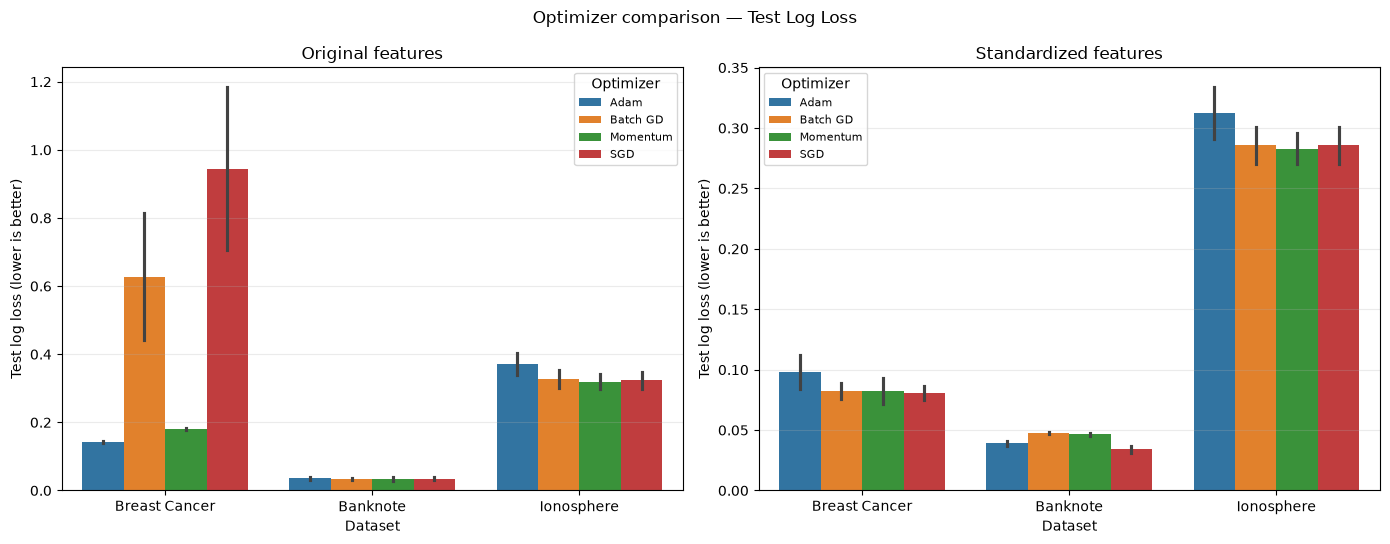

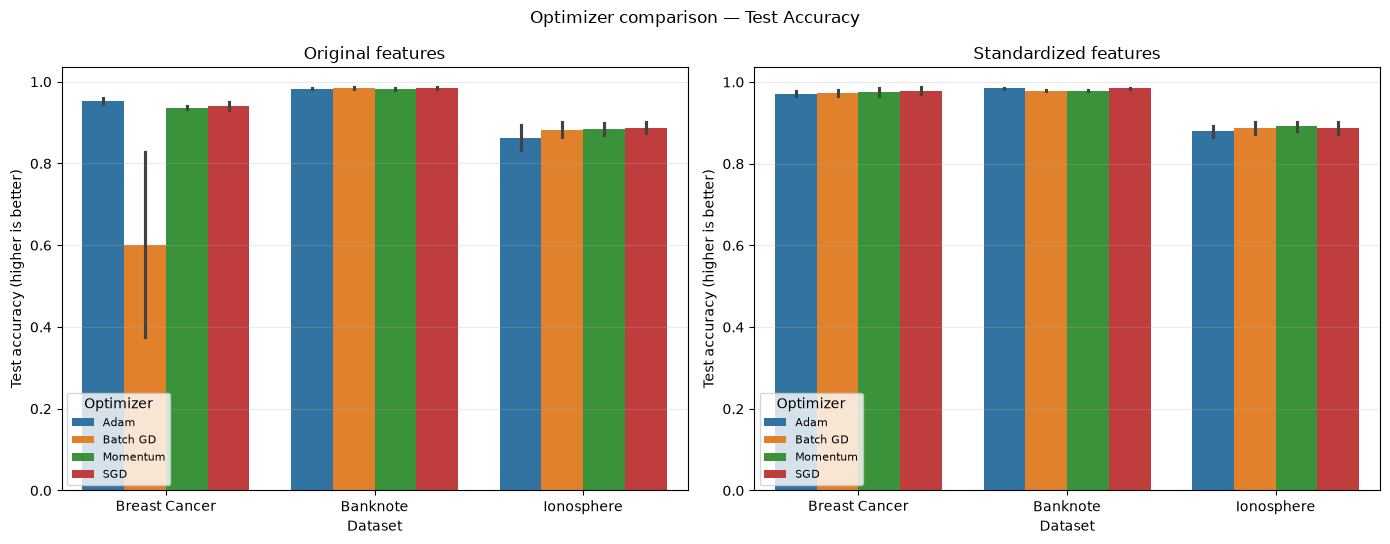

In [10]:
for metric, ylabel, filename in [
    ("Test Log Loss", "Test log loss (lower is better)", "real_data_test_log_loss.png"),
    ("Test Accuracy", "Test accuracy (higher is better)", "real_data_test_accuracy.png"),
]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)
    for ax, condition in zip(axes, CONDITIONS):
        subset = final_results[final_results["Condition"] == condition]
        sns.barplot(
            data=subset,
            x="Dataset",
            y=metric,
            hue="Optimizer",
            errorbar="sd",
            ax=ax,
        )
        ax.set_title(f"{condition.capitalize()} features")
        ax.set_xlabel("Dataset")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(title="Optimizer", fontsize=8)
    fig.suptitle(f"Optimizer comparison — {metric}")
    fig.tight_layout()
    fig.savefig(FIGURES_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

### A9. Real-dataset interpretation notes

Report means and standard deviations together with omnibus and pairwise tests. Within-group and global Holm-adjusted pairwise results are kept distinct: the latter applies the more conservative correction across the entire family of pairwise comparisons.

The three datasets have different feature dimensions and feature meanings. The project therefore does not train a model on one dataset and test it on another. Instead, it applies a common, prespecified experimental protocol independently to each dataset and compares whether optimizer and feature-scaling patterns replicate across these distinct classification problems. The next section formalizes this cross-dataset replication analysis.


---

## Part A10 — Cross-dataset replication validation

### A10.1 What is being validated

Cross-dataset validation here means **replication of experimental patterns across three distinct datasets**. The datasets have different numbers and meanings of input features, so direct train-on-A/test-on-B transfer would be invalid without inventing a shared feature representation. Instead, the same logistic-regression implementation, optimizer definitions, learning-rate search grids, split rules, preprocessing rules, and evaluation metrics are applied separately to each dataset.

The analysis asks:

1. Does standardization improve test accuracy and/or test log loss consistently across datasets and optimizers?
2. Are optimizer rankings reasonably consistent across datasets and feature conditions?
3. Do the observed scaling effects occur alongside reductions in the local Hessian condition number?

The results are descriptive replication evidence across **three datasets**. We do not run a meta-analysis or claim universal generalization from only three datasets.

In [11]:
# Pair original and standardized results by dataset, optimizer, and development-split seed.
PAIR_KEYS = ["Dataset", "Optimizer", "Seed"]

accuracy_wide = final_results.pivot(
    index=PAIR_KEYS, columns="Condition", values="Test Accuracy"
).reset_index()
accuracy_wide = accuracy_wide.rename(columns={
    "original": "Original Test Accuracy",
    "standardized": "Standardized Test Accuracy",
})

loss_wide = final_results.pivot(
    index=PAIR_KEYS, columns="Condition", values="Test Log Loss"
).reset_index()
loss_wide = loss_wide.rename(columns={
    "original": "Original Test Log Loss",
    "standardized": "Standardized Test Log Loss",
})

cross_dataset_scaling_effects = accuracy_wide.merge(
    loss_wide, on=PAIR_KEYS, validate="one_to_one"
)
cross_dataset_scaling_effects["Accuracy Change (Standardized - Original)"] = (
    cross_dataset_scaling_effects["Standardized Test Accuracy"]
    - cross_dataset_scaling_effects["Original Test Accuracy"]
)
cross_dataset_scaling_effects["Log Loss Improvement (Original - Standardized)"] = (
    cross_dataset_scaling_effects["Original Test Log Loss"]
    - cross_dataset_scaling_effects["Standardized Test Log Loss"]
)

cross_dataset_scaling_by_optimizer = (
    cross_dataset_scaling_effects.groupby(["Dataset", "Optimizer"])
    .agg(
        **{
            "Mean Accuracy Change": (
                "Accuracy Change (Standardized - Original)", "mean"
            ),
            "SD Accuracy Change": (
                "Accuracy Change (Standardized - Original)", "std"
            ),
            "Mean Log Loss Improvement": (
                "Log Loss Improvement (Original - Standardized)", "mean"
            ),
            "SD Log Loss Improvement": (
                "Log Loss Improvement (Original - Standardized)", "std"
            ),
            "Accuracy-Improved Seeds": (
                "Accuracy Change (Standardized - Original)",
                lambda values: int((values > 0).sum()),
            ),
            "Log-Loss-Improved Seeds": (
                "Log Loss Improvement (Original - Standardized)",
                lambda values: int((values > 0).sum()),
            ),
            "Evaluation Seeds": ("Seed", "nunique"),
        }
    )
    .reset_index()
)

# Dataset-level pattern summary: average the four optimizer effects within each dataset.
dataset_scaling_summary = (
    cross_dataset_scaling_by_optimizer.groupby("Dataset")
    .agg(
        **{
            "Mean Accuracy Change Across Optimizers": ("Mean Accuracy Change", "mean"),
            "Mean Log Loss Improvement Across Optimizers": (
                "Mean Log Loss Improvement", "mean"
            ),
            "Optimizers with Accuracy Improvement": (
                "Mean Accuracy Change", lambda values: int((values > 0).sum())
            ),
            "Optimizers with Log Loss Improvement": (
                "Mean Log Loss Improvement", lambda values: int((values > 0).sum())
            ),
        }
    )
    .reset_index()
)

# Optimizer ranking: rank 1 is best within each dataset/condition.
optimizer_performance_means = (
    final_results.groupby(["Dataset", "Condition", "Optimizer"])
    [["Test Accuracy", "Test Log Loss"]]
    .mean()
    .reset_index()
)
optimizer_performance_means["Accuracy Rank"] = (
    optimizer_performance_means.groupby(["Dataset", "Condition"])["Test Accuracy"]
    .rank(ascending=False, method="average")
)
optimizer_performance_means["Log Loss Rank"] = (
    optimizer_performance_means.groupby(["Dataset", "Condition"])["Test Log Loss"]
    .rank(ascending=True, method="average")
)

cross_dataset_optimizer_ranks = (
    optimizer_performance_means.groupby(["Dataset", "Optimizer"])
    [["Accuracy Rank", "Log Loss Rank"]]
    .mean()
    .reset_index()
)
cross_dataset_optimizer_rank_summary = (
    cross_dataset_optimizer_ranks.groupby("Optimizer")
    [["Accuracy Rank", "Log Loss Rank"]]
    .mean()
    .reset_index()
    .sort_values("Log Loss Rank")
)

print("Paired standardization effects by dataset and optimizer:")
display(cross_dataset_scaling_by_optimizer.round(4))
print("Optimizer ranking consistency across datasets (lower mean rank is better):")
display(cross_dataset_optimizer_ranks.round(3))
print("Overall descriptive mean optimizer ranks:")
display(cross_dataset_optimizer_rank_summary.round(3))


Paired standardization effects by dataset and optimizer:


,Dataset,Optimizer,Mean Accuracy Change,SD Accuracy Change,Mean Log Loss Improvement,SD Log Loss Improvement,Accuracy-Improved Seeds,Log-Loss-Improved Seeds,Evaluation Seeds
0,Banknote,Adam,0.0011,0.0025,-0.0036,0.0036,4,1,10
1,Banknote,Batch GD,-0.0055,0.0026,-0.0136,0.0024,0,0,10
2,Banknote,Momentum,-0.0044,0.0029,-0.0123,0.0046,0,0,10
3,Banknote,SGD,0.0004,0.0011,0.0004,0.0021,1,6,10
4,Breast Cancer,Adam,0.0175,0.0109,0.0434,0.0148,10,10,10
5,Breast Cancer,Batch GD,0.3719,0.2302,0.5455,0.1882,10,10,10
6,Breast Cancer,Momentum,0.0386,0.0103,0.0983,0.0133,10,10,10
7,Breast Cancer,SGD,0.0368,0.0115,0.8636,0.2398,10,10,10
8,Ionosphere,Adam,0.0155,0.0378,0.0592,0.0268,4,10,10
9,Ionosphere,Batch GD,0.0042,0.0200,0.0407,0.0157,4,10,10


Optimizer ranking consistency across datasets (lower mean rank is better):


,Dataset,Optimizer,Accuracy Rank,Log Loss Rank
0,Banknote,Adam,2.25,3.0
1,Banknote,Batch GD,2.50,2.5
2,Banknote,Momentum,3.75,2.5
3,Banknote,SGD,1.50,2.0
4,Breast Cancer,Adam,2.50,2.5
5,Breast Cancer,Batch GD,3.50,2.5
6,Breast Cancer,Momentum,2.50,2.5
7,Breast Cancer,SGD,1.50,2.5
8,Ionosphere,Adam,4.00,4.0
9,Ionosphere,Batch GD,2.75,2.5


Overall descriptive mean optimizer ranks:


,Optimizer,Accuracy Rank,Log Loss Rank
2,Momentum,2.583,2.000
3,SGD,1.583,2.333
1,Batch GD,2.917,2.500
0,Adam,2.917,3.167


In [12]:
# Re-estimate local Hessian conditioning on the tuning training partition only.
# This keeps the conditioning diagnostic independent of the fixed test holdout.
conditioning_records = []
for dataset_name in DATASET_NAMES:
    holdout = fixed_holdouts[dataset_name]
    for condition in CONDITIONS:
        tuning_partition = prepare_training_validation(
            holdout["X_development"],
            holdout["y_development"],
            condition,
            seed=TUNING_CONFIG["seed"],
            validation_fraction=TUNING_CONFIG["validation_fraction_of_development"],
        )
        X_train_bias = logistic_regression.add_intercept(
            tuning_partition["X_train"]
        )
        theta_zero = np.zeros(X_train_bias.shape[1], dtype=float)
        hessian = logistic_regression.compute_hessian(
            X_train_bias, theta_zero, l2=TUNING_CONFIG["l2"]
        )
        eigenvalues = np.linalg.eigvalsh(hessian)
        condition_number = float(np.linalg.cond(hessian))
        conditioning_records.append({
            "Dataset": dataset_name,
            "Condition": condition,
            "Minimum Eigenvalue": float(eigenvalues.min()),
            "Maximum Eigenvalue": float(eigenvalues.max()),
            "Condition Number": condition_number,
            "Evaluation Point": "theta = 0",
            "Data Used": "Tuning training partition from development pool",
        })

cross_dataset_conditioning = pd.DataFrame(conditioning_records)
conditioning_wide = cross_dataset_conditioning.pivot(
    index="Dataset", columns="Condition", values="Condition Number"
).reset_index()
conditioning_wide = conditioning_wide.rename(columns={
    "original": "Original Condition Number",
    "standardized": "Standardized Condition Number",
})
conditioning_wide["Condition-Number Reduction (%)"] = 100.0 * (
    1.0 - conditioning_wide["Standardized Condition Number"] /
    conditioning_wide["Original Condition Number"]
)

cross_dataset_validation_summary = dataset_scaling_summary.merge(
    conditioning_wide, on="Dataset", validate="one_to_one"
)

# Replication counts across the three datasets, summarized separately for each optimizer.
cross_dataset_optimizer_consistency = (
    cross_dataset_scaling_by_optimizer.groupby("Optimizer")
    .agg(
        **{
            "Datasets with Positive Mean Accuracy Change": (
                "Mean Accuracy Change", lambda values: int((values > 0).sum())
            ),
            "Datasets with Positive Mean Log Loss Improvement": (
                "Mean Log Loss Improvement", lambda values: int((values > 0).sum())
            ),
            "Mean Accuracy Change Across Datasets": ("Mean Accuracy Change", "mean"),
            "Mean Log Loss Improvement Across Datasets": (
                "Mean Log Loss Improvement", "mean"
            ),
        }
    )
    .reset_index()
)

# Save auditable tables for the notebook, paper, and repository.
cross_dataset_scaling_effects.to_csv(
    TABLES_PATH / "cross_dataset_scaling_effects_by_seed.csv", index=False
)
cross_dataset_scaling_by_optimizer.to_csv(
    TABLES_PATH / "cross_dataset_scaling_effects.csv", index=False
)
cross_dataset_optimizer_ranks.to_csv(
    TABLES_PATH / "cross_dataset_optimizer_ranks.csv", index=False
)
cross_dataset_optimizer_rank_summary.to_csv(
    TABLES_PATH / "cross_dataset_optimizer_rank_summary.csv", index=False
)
cross_dataset_conditioning.to_csv(
    TABLES_PATH / "cross_dataset_conditioning.csv", index=False
)
cross_dataset_validation_summary.to_csv(
    TABLES_PATH / "cross_dataset_validation_summary.csv", index=False
)
cross_dataset_optimizer_consistency.to_csv(
    TABLES_PATH / "cross_dataset_optimizer_consistency.csv", index=False
)
holdout_audit_df.to_csv(TABLES_PATH / "fixed_test_holdout_audit.csv", index=False)

print("Cross-dataset replication summary:")
display(cross_dataset_validation_summary.round(4))
print("Optimizer consistency across datasets:")
display(cross_dataset_optimizer_consistency.round(4))


Cross-dataset replication summary:


,Dataset,Mean Accuracy Change Across Optimizers,Mean Log Loss Improvement Across Optimizers,Optimizers with Accuracy Improvement,Optimizers with Log Loss Improvement,Original Condition Number,Standardized Condition Number,Condition-Number Reduction (%)
0,Banknote,-0.0021,-0.0073,2,1,1.336904e+02,12.3169,90.787
1,Breast Cancer,0.1162,0.3877,4,4,2.772066e+12,140018.6030,100.000
2,Ionosphere,0.0067,0.0436,3,4,4.876723e+02,166.9986,65.756


Optimizer consistency across datasets:


,Optimizer,Datasets with Positive Mean Accuracy Change,Datasets with Positive Mean Log Loss Improvement,Mean Accuracy Change Across Datasets,Mean Log Loss Improvement Across Datasets
0,Adam,3,2,0.0114,0.0330
1,Batch GD,2,2,0.1236,0.1909
2,Momentum,2,2,0.0138,0.0409
3,SGD,2,3,0.0124,0.3006


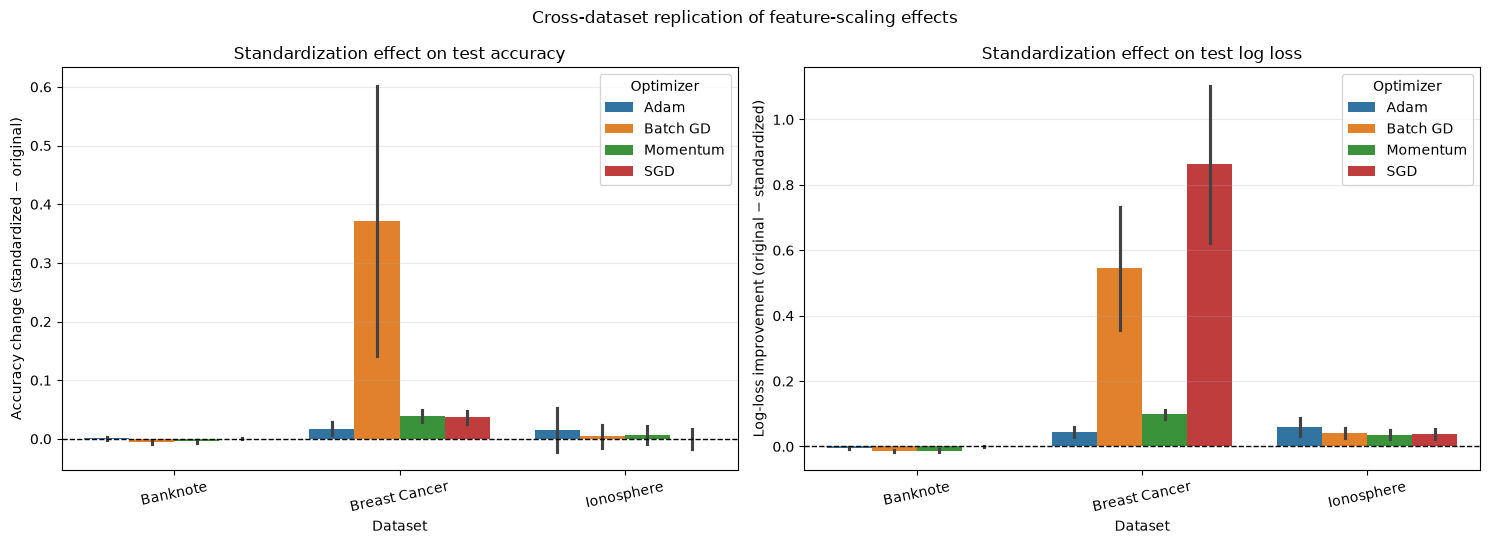

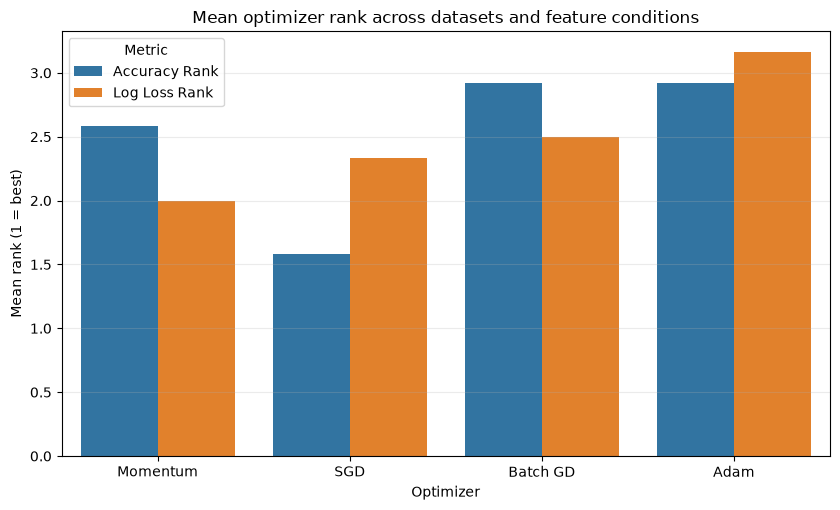

In [13]:
# Visualize paired standardization effects. Positive values favor standardization
# for both plotted metrics by construction of the effect definitions.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(
    data=cross_dataset_scaling_effects,
    x="Dataset",
    y="Accuracy Change (Standardized - Original)",
    hue="Optimizer",
    errorbar="sd",
    ax=axes[0],
)
axes[0].axhline(0.0, color="black", linewidth=1, linestyle="--")
axes[0].set_title("Standardization effect on test accuracy")
axes[0].set_ylabel("Accuracy change (standardized − original)")
axes[0].set_xlabel("Dataset")
axes[0].tick_params(axis="x", rotation=12)
axes[0].grid(axis="y", alpha=0.25)

sns.barplot(
    data=cross_dataset_scaling_effects,
    x="Dataset",
    y="Log Loss Improvement (Original - Standardized)",
    hue="Optimizer",
    errorbar="sd",
    ax=axes[1],
)
axes[1].axhline(0.0, color="black", linewidth=1, linestyle="--")
axes[1].set_title("Standardization effect on test log loss")
axes[1].set_ylabel("Log-loss improvement (original − standardized)")
axes[1].set_xlabel("Dataset")
axes[1].tick_params(axis="x", rotation=12)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Cross-dataset replication of feature-scaling effects")
fig.tight_layout()
fig.savefig(
    FIGURES_PATH / "cross_dataset_scaling_effects.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5.2))
rank_plot = cross_dataset_optimizer_rank_summary.melt(
    id_vars="Optimizer",
    value_vars=["Accuracy Rank", "Log Loss Rank"],
    var_name="Metric",
    value_name="Mean Rank",
)
sns.barplot(data=rank_plot, x="Optimizer", y="Mean Rank", hue="Metric", ax=ax)
ax.set_title("Mean optimizer rank across datasets and feature conditions")
ax.set_ylabel("Mean rank (1 = best)")
ax.set_xlabel("Optimizer")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_PATH / "cross_dataset_optimizer_ranks.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### A10.2 Interpretation and limits

Interpret the cross-dataset tables as a structured replication check:

- A positive `Accuracy Change (Standardized - Original)` favors standardization for accuracy.
- A positive `Log Loss Improvement (Original - Standardized)` favors standardization for log loss.
- `Datasets with Positive Mean ...` counts how many of the three datasets show a positive mean effect for a given optimizer. It is a consistency count, not a significance test.
- Optimizer ranks are calculated within each dataset/feature-condition combination; a lower mean rank is better. Rankings are descriptive and should not be treated as universal optimizer rankings.
- Hessian condition numbers are local diagnostics at zero initialization, estimated from the tuning training partition. Compare them alongside performance, but do not infer causality from three observational datasets.

**Scope:** this meets a replication-based interpretation of cross-dataset validation: common methodology, separate dataset-level evaluation, and an explicit comparison of whether patterns recur. It does not establish transfer to a new dataset with unseen feature semantics. A future transfer study would require datasets with genuinely aligned features and compatible target definitions.

---

## Part B — Controlled quadratic conditioning experiment

### B1. Objective and mathematical setup

We minimize

$$
 f(\theta)=\frac{1}{2}\theta^T H\theta,
 \qquad H=\begin{bmatrix}1&0\\0&\kappa\end{bmatrix}.
$$

The eigenvalues are \(1\) and (κ), so the Hessian condition number is (κ). The minimizer is _θ*_=(0,0), with minimum loss zero. We examine (κ) in {1,10,100,1000,10000}.

For SGD, one coordinate is sampled uniformly at each update and its gradient component is multiplied by the dimension. This is an unbiased stochastic coordinate-gradient estimator; it is not mini-batch sampling from the real datasets.

Momentum uses the project's normalized exponential moving average of gradients, not the unnormalized heavy-ball convention. Learning-rate grids are therefore defined for the actual update implemented in `src/optimizers.py`.

In [14]:
QUADRATIC_CONFIG = {
    "condition_numbers": [1, 10, 100, 1000, 10000],
    "tuning_seed": 42,
    "evaluation_seeds": list(range(10)),
    "max_updates": 5000,
    "convergence_threshold": 1e-8,
    "convergence_window": 10,
    "momentum_beta": 0.9,
}
QUADRATIC_OPTIMIZERS = ["Adam", "Batch GD", "Momentum", "SGD"]


def quadratic_loss(theta, H):
    with np.errstate(over="ignore", invalid="ignore"):
        value = 0.5 * theta.T @ H @ theta
    return float(value) if np.isfinite(value) else np.inf


def quadratic_gradient(theta, H):
    return H @ theta


def create_hessian(condition_number):
    if condition_number < 1:
        raise ValueError("condition_number must be at least 1.")
    return np.diag([1.0, float(condition_number)])


def finite_difference_gradient(function, point, epsilon=1e-6):
    point = np.asarray(point, dtype=float)
    result = np.zeros_like(point)
    for index in range(point.size):
        plus, minus = point.copy(), point.copy()
        plus[index] += epsilon
        minus[index] -= epsilon
        result[index] = (function(plus) - function(minus)) / (2 * epsilon)
    return result


check_theta = np.array([5.0, 5.0])
check_H = create_hessian(100)
analytic = quadratic_gradient(check_theta, check_H)
numerical = finite_difference_gradient(
    lambda candidate: quadratic_loss(candidate, check_H), check_theta
)
assert np.allclose(analytic, numerical, atol=1e-5)
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    assert np.isclose(np.linalg.cond(H), kappa)
print("Quadratic gradient and Hessian-condition checks passed.")
print("Analytical gradient:", analytic)
print("Finite-difference gradient:", numerical)

Quadratic gradient and Hessian-condition checks passed.
Analytical gradient: [  5. 500.]
Finite-difference gradient: [  4.99999999 500.0000001 ]


### B2. Optimizer runner and convergence criterion

A run is considered converged when the objective remains at or below (10⁻⁸) for ten consecutive updates. Every run is limited to 5,000 updates. A run that reaches the budget without meeting the threshold is **not converged**; if all values remain finite, it is still considered stable.

Equal update budgets do not imply equal arithmetic cost: full-gradient methods evaluate both coordinates at every update, while SGD samples one coordinate. Report this distinction when interpreting the results.

In [15]:
def stochastic_quadratic_gradient(theta, H, rng):
    dimension = len(theta)
    coordinate = rng.integers(dimension)
    gradient = np.zeros_like(theta, dtype=float)
    gradient[coordinate] = dimension * H[coordinate, coordinate] * theta[coordinate]
    return gradient


def create_quadratic_optimizer(name, learning_rate):
    if name in ("Batch GD", "SGD"):
        return optimizers.GradientDescent(learning_rate)
    if name == "Momentum":
        return optimizers.Momentum(
            learning_rate, beta=QUADRATIC_CONFIG["momentum_beta"]
        )
    if name == "Adam":
        return optimizers.Adam(learning_rate)
    raise ValueError(f"Unknown optimizer: {name}")


def run_quadratic_optimizer(
    H, optimizer_name, learning_rate, seed,
    initial_theta=None,
):
    rng = np.random.default_rng(seed)
    initial_rng = np.random.default_rng(seed + 1_000_003)
    theta = (
        initial_rng.uniform(-5.0, 5.0, size=2)
        if initial_theta is None
        else np.asarray(initial_theta, dtype=float).copy()
    )
    initial_theta_used = theta.copy()
    if theta.shape != (2,) or not np.all(np.isfinite(theta)):
        raise ValueError("initial_theta must be a finite two-dimensional vector.")

    optimizer = create_quadratic_optimizer(optimizer_name, learning_rate)
    optimizer.reset(len(theta))
    loss_history = [quadratic_loss(theta, H)]
    stable = bool(np.isfinite(loss_history[0]))
    consecutive_below = 0
    convergence_update = None

    for update in range(1, QUADRATIC_CONFIG["max_updates"] + 1):
        if not stable:
            break
        if optimizer_name == "SGD":
            gradient = stochastic_quadratic_gradient(theta, H, rng)
        else:
            gradient = quadratic_gradient(theta, H)

        theta = optimizer.step(theta, gradient)
        if not np.all(np.isfinite(theta)):
            stable = False
            break
        current_loss = quadratic_loss(theta, H)
        if not np.isfinite(current_loss):
            stable = False
            break
        loss_history.append(current_loss)

        if current_loss <= QUADRATIC_CONFIG["convergence_threshold"]:
            consecutive_below += 1
        else:
            consecutive_below = 0
        if consecutive_below >= QUADRATIC_CONFIG["convergence_window"]:
            convergence_update = update
            break

    return {
        "initial_theta": initial_theta_used,
        "final_theta": theta,
        "final_loss": loss_history[-1],
        "loss_history": loss_history,
        "parameter_updates": len(loss_history) - 1,
        "convergence_update": convergence_update,
        "converged": convergence_update is not None,
        "stable": stable,
    }

### B3. Learning-rate tuning

Each optimizer and condition number has its own candidate grid. The tuning seed (42) is separate from the ten evaluation seeds. If at least one stable candidate converges, selection minimizes the update count to sustained convergence, breaking ties by final loss. If no candidate converges, selection uses the stable candidate with the lowest final loss. Such a selected configuration must be reported as **not converged during tuning**.

A rate selected at the minimum or maximum of a grid indicates a boundary choice. The reported performance is therefore the best result among the tested candidates; it does not prove that the global best learning rate was found.

In [16]:
def quadratic_learning_rate_grid(kappa):
    beta = QUADRATIC_CONFIG["momentum_beta"]
    batch_max = 1.8 / kappa
    sgd_max = 0.9 / kappa
    momentum_max = 0.9 * 2 * (1 + beta) / ((1 - beta) * kappa)
    grids = {
        "Batch GD": batch_max * np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 0.85, 1.0]),
        "SGD": sgd_max * np.array([0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]),
        "Momentum": momentum_max * np.array([0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]),
        "Adam": np.array([0.001, 0.003, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]),
    }
    return {
        name: np.unique(np.round(values, 12)).tolist()
        for name, values in grids.items()
    }


def tune_quadratic_optimizer(H, optimizer_name, learning_rates):
    records = []
    for learning_rate in learning_rates:
        result = run_quadratic_optimizer(
            H, optimizer_name, learning_rate,
            seed=QUADRATIC_CONFIG["tuning_seed"],
        )
        records.append(
            {
                "Optimizer": optimizer_name,
                "Learning Rate": learning_rate,
                "Final Loss": result["final_loss"],
                "Converged": result["converged"],
                "Stable": result["stable"],
                "Convergence Update": result["convergence_update"],
                "Parameter Updates": result["parameter_updates"],
            }
        )
    candidates = pd.DataFrame(records)
    stable = candidates[candidates["Stable"]]
    if stable.empty:
        raise RuntimeError(f"No stable candidate found for {optimizer_name}.")
    converged = stable[stable["Converged"]]
    if not converged.empty:
        best = converged.sort_values(
            ["Convergence Update", "Final Loss"]
        ).iloc[0]
    else:
        best = stable.sort_values("Final Loss").iloc[0]
    return candidates, best


quadratic_tuning_frames = []
quadratic_selected = {}
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    grids = quadratic_learning_rate_grid(kappa)
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        candidates, best = tune_quadratic_optimizer(
            H, optimizer_name, grids[optimizer_name]
        )
        candidates["Condition Number"] = kappa
        quadratic_tuning_frames.append(candidates)
        quadratic_selected[(kappa, optimizer_name)] = best.to_dict()

quadratic_tuning_df = pd.concat(quadratic_tuning_frames, ignore_index=True)
quadratic_selected_rows = []
for (kappa, optimizer_name), best in quadratic_selected.items():
    grid = quadratic_learning_rate_grid(kappa)[optimizer_name]
    rate = float(best["Learning Rate"])
    at_min = bool(np.isclose(rate, min(grid)))
    at_max = bool(np.isclose(rate, max(grid)))
    quadratic_selected_rows.append(
        {
            "Condition Number": kappa,
            "Optimizer": optimizer_name,
            "Selected Learning Rate": rate,
            "Tuning Converged": bool(best["Converged"]),
            "Tuning Final Loss": float(best["Final Loss"]),
            "At Search Boundary": at_min or at_max,
            "Boundary": "Minimum" if at_min else ("Maximum" if at_max else "Interior"),
        }
    )
quadratic_selected_df = pd.DataFrame(quadratic_selected_rows)

display(quadratic_selected_df)
quadratic_tuning_df.to_csv(TABLES_PATH / "quadratic_tuning_all_conditions.csv", index=False)
quadratic_selected_df.to_csv(TABLES_PATH / "quadratic_selected_learning_rates.csv", index=False)

,Condition Number,Optimizer,Selected Learning Rate,Tuning Converged,Tuning Final Loss,At Search Boundary,Boundary
0,1,Adam,0.03000,True,9.704603e-09,False,Interior
1,1,Batch GD,0.90000,True,8.249675e-27,False,Interior
2,1,Momentum,0.68400,True,5.307307e-09,True,Minimum
3,1,SGD,0.45000,True,4.885543e-15,False,Interior
4,10,Adam,0.10000,True,9.593844e-09,False,Interior
5,10,Batch GD,0.15300,True,4.182992e-10,False,Interior
6,10,Momentum,0.34200,True,5.216471e-09,False,Interior
7,10,SGD,0.09000,True,7.229253e-10,True,Maximum
8,100,Adam,0.20000,True,2.270694e-09,False,Interior
9,100,Batch GD,0.01800,True,7.102541e-09,True,Maximum


### B4. Repeated evaluation

The selected rates are frozen before evaluation. For each seed, all optimizers start from the same seed-specific initial parameter vector. SGD uses a separate pseudorandom stream for coordinate selection. The resulting design contains (5 condition numbers) x (4 optimizers) x (10 seeds) = **200 runs**.

In [17]:
quadratic_evaluation_records = []
quadratic_evaluation_histories = {}

for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        selected_rate = quadratic_selected[(kappa, optimizer_name)]["Learning Rate"]
        for seed in QUADRATIC_CONFIG["evaluation_seeds"]:
            result = run_quadratic_optimizer(
                H,
                optimizer_name,
                selected_rate,
                seed=seed,
            )
            quadratic_evaluation_records.append(
                {
                    "Condition Number": kappa,
                    "Optimizer": optimizer_name,
                    "Seed": seed,
                    "Initial Theta 1": result["initial_theta"][0],
                    "Initial Theta 2": result["initial_theta"][1],
                    "Learning Rate": selected_rate,
                    "Final Loss": result["final_loss"],
                    "Converged": result["converged"],
                    "Stable": result["stable"],
                    "Convergence Update": result["convergence_update"],
                    "Parameter Updates": result["parameter_updates"],
                }
            )
            quadratic_evaluation_histories[(kappa, optimizer_name, seed)] = result["loss_history"]

quadratic_evaluation_df = pd.DataFrame(quadratic_evaluation_records)
expected_quadratic_runs = (
    len(QUADRATIC_CONFIG["condition_numbers"]) *
    len(QUADRATIC_OPTIMIZERS) *
    len(QUADRATIC_CONFIG["evaluation_seeds"])
)
assert len(quadratic_evaluation_df) == expected_quadratic_runs
assert not quadratic_evaluation_df.duplicated(
    ["Condition Number", "Optimizer", "Seed"]
).any()
quadratic_evaluation_df.to_csv(TABLES_PATH / "quadratic_repeated_evaluation.csv", index=False)

print("Quadratic evaluation runs:", len(quadratic_evaluation_df))
print("Unstable runs:", int((~quadratic_evaluation_df["Stable"]).sum()))
display(
    quadratic_evaluation_df.groupby(["Condition Number", "Optimizer"])
    .agg(
        Runs=("Seed", "count"),
        Converged_Runs=("Converged", "sum"),
        Convergence_Rate=("Converged", "mean"),
        Median_Final_Loss=("Final Loss", "median"),
        Median_Updates_Used=("Parameter Updates", "median"),
    )
    .round(8)
)

Quadratic evaluation runs: 200
Unstable runs: 0


Runs  Converged_Runs  Convergence_Rate  \
Condition Number Optimizer                                           
1                Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
10               Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
100              Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
1000             Adam         10              10               1.0   
                 Batch GD     10               1               0.1   
                 Momentum     10              10               1.0   
                 SGD          10               0               0.0   
10000            Adam         10              10               1.0   
                 Batch GD     10               0               0.0   
                 Momentum     10              10               1.0   
                 SGD          10               0               0.0   

                            Median_Final_Loss  Median_Updates_Used  
Condition Number Optimizer                                          
1                Adam            0.000000e+00                447.5  
                 Batch GD        0.000000e+00                 14.0  
                 Momentum        1.000000e-08                202.5  
                 SGD             0.000000e+00                 20.0  
10               Adam            0.000000e+00                214.0  
                 Batch GD        0.000000e+00                 70.5  
                 Momentum        0.000000e+00                209.5  
                 SGD             0.000000e+00                116.0  
100              Adam            0.000000e+00                229.5  
                 Batch GD        1.000000e-08                567.5  
                 Momentum        0.000000e+00                230.5  
                 SGD             1.000000e-08               1115.5  
1000             Adam            0.000000e+00                251.0  
                 Batch GD        9.000000e-08               5000.0  
                 Momentum        0.000000e+00                305.5  
                 SGD             6.770300e-04               5000.0  
10000            Adam            0.000000e+00                271.5  
                 Batch GD        1.044860e+00               5000.0  
                 Momentum        1.000000e-08               2882.0  
                 SGD             2.535942e+00               5000.0

### B5. Convergence trajectories and convergence-speed summary

The convergence histories have different lengths because runs stop when the sustained-convergence condition is met. For plotting, each completed history is extended horizontally at its final loss. This keeps all ten runs represented at every plotted update and avoids calculating late medians from only the slower, still-running subset.

For convergence speed, update counts are summarized **only among runs that actually converged**. Non-converged runs are reported separately and are not treated as if they converged at the 5,000-update limit.

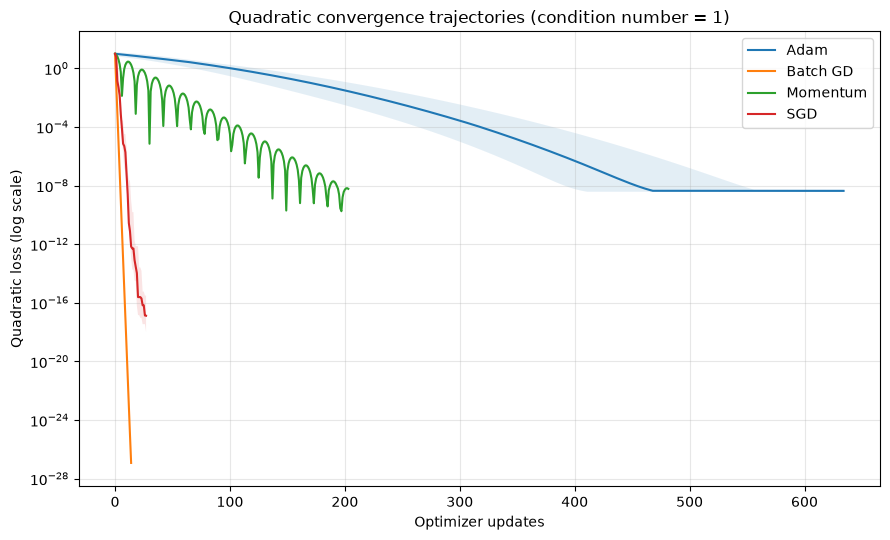

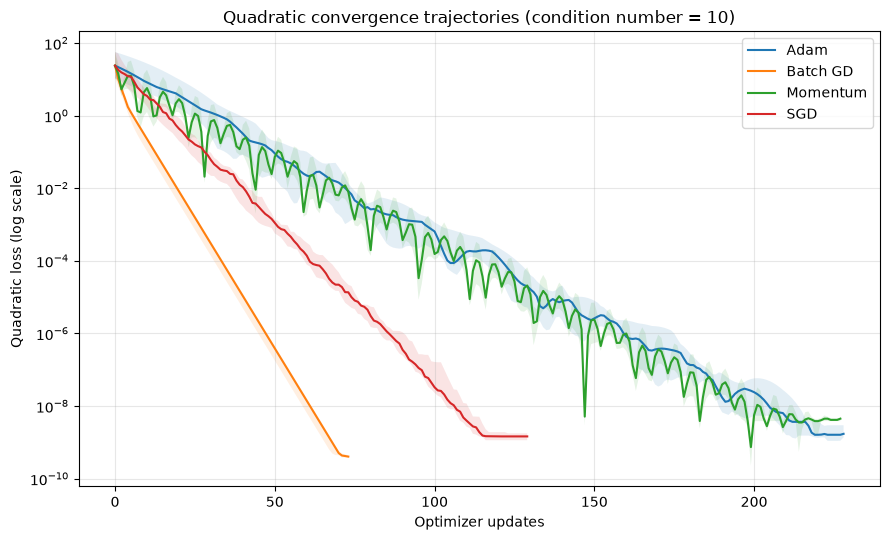

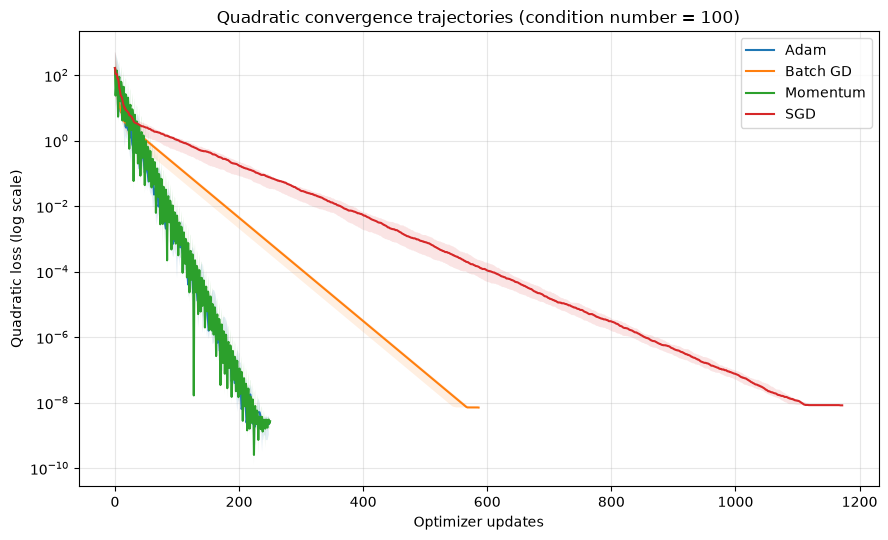

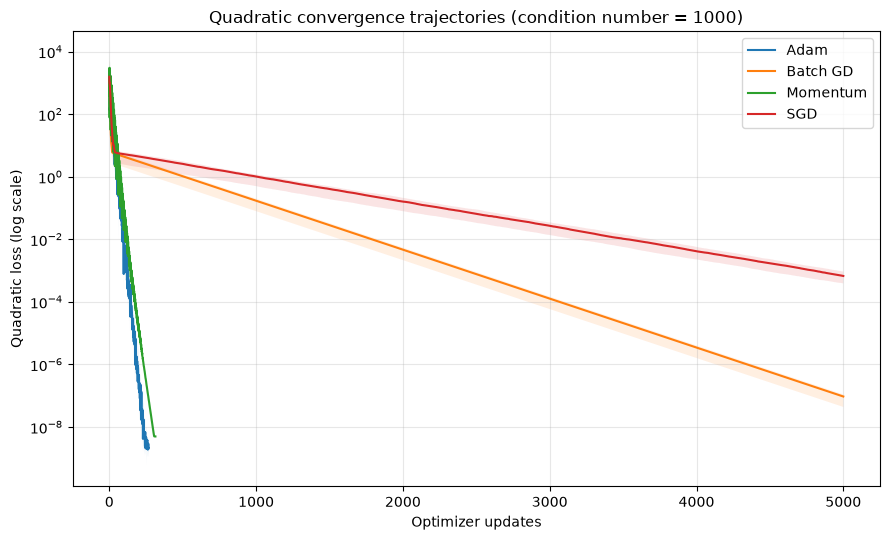

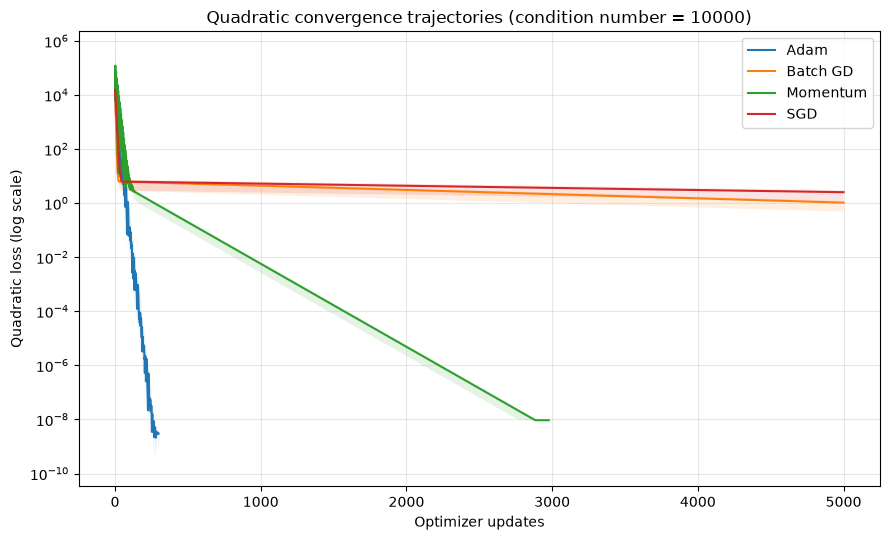

In [18]:
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        histories = [
            np.asarray(
                quadratic_evaluation_histories[(kappa, optimizer_name, seed)],
                dtype=float,
            )
            for seed in QUADRATIC_CONFIG["evaluation_seeds"]
        ]
        max_length = max(map(len, histories))
        aligned = np.empty((len(histories), max_length), dtype=float)
        for row, history in enumerate(histories):
            aligned[row, :len(history)] = history
            aligned[row, len(history):] = history[-1]

        median = np.median(aligned, axis=0)
        lower = np.percentile(aligned, 25, axis=0)
        upper = np.percentile(aligned, 75, axis=0)
        updates = np.arange(max_length)
        # A small plotting floor avoids log(0) if floating-point underflow occurs.
        floor = np.finfo(float).tiny
        ax.plot(updates, np.maximum(median, floor), label=optimizer_name)
        ax.fill_between(
            updates,
            np.maximum(lower, floor),
            np.maximum(upper, floor),
            alpha=0.12,
        )

    ax.set_yscale("log")
    ax.set_xlabel("Optimizer updates")
    ax.set_ylabel("Quadratic loss (log scale)")
    ax.set_title(f"Quadratic convergence trajectories (condition number = {kappa})")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        FIGURES_PATH / f"quadratic_convergence_kappa_{kappa}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

In [19]:
def summarize_quadratic_group(group):
    converged_group = group[group["Converged"]]
    return pd.Series(
        {
            "Runs": len(group),
            "Converged Runs": len(converged_group),
            "Convergence Rate": group["Converged"].mean(),
            "Median Updates to Convergence": (
                converged_group["Convergence Update"].median()
                if len(converged_group) else np.nan
            ),
            "Mean Updates to Convergence": (
                converged_group["Convergence Update"].mean()
                if len(converged_group) else np.nan
            ),
            "Median Updates Used": group["Parameter Updates"].median(),
            "Median Final Loss": group["Final Loss"].median(),
            "Mean Final Loss": group["Final Loss"].mean(),
        }
    )

quadratic_summary = (
    quadratic_evaluation_df.groupby(["Condition Number", "Optimizer"])
    .apply(summarize_quadratic_group, include_groups=False)
    .reset_index()
)
display(quadratic_summary.round(8))
quadratic_summary.to_csv(TABLES_PATH / "quadratic_convergence_summary.csv", index=False)

,Condition Number,Optimizer,Runs,Converged Runs,Convergence Rate,Median Updates to Convergence,Mean Updates to Convergence,Median Updates Used,Median Final Loss,Mean Final Loss
0,1,Adam,10.0,10.0,1.0,447.5,419.2,447.5,0.000000e+00,0.000000e+00
1,1,Batch GD,10.0,10.0,1.0,14.0,13.9,14.0,0.000000e+00,0.000000e+00
2,1,Momentum,10.0,10.0,1.0,202.5,196.5,202.5,1.000000e-08,1.000000e-08
3,1,SGD,10.0,10.0,1.0,20.0,21.1,20.0,0.000000e+00,0.000000e+00
4,10,Adam,10.0,10.0,1.0,214.0,210.4,214.0,0.000000e+00,0.000000e+00
5,10,Batch GD,10.0,10.0,1.0,70.5,67.8,70.5,0.000000e+00,0.000000e+00
6,10,Momentum,10.0,10.0,1.0,209.5,210.0,209.5,0.000000e+00,0.000000e+00
7,10,SGD,10.0,10.0,1.0,116.0,115.4,116.0,0.000000e+00,0.000000e+00
8,100,Adam,10.0,10.0,1.0,229.5,228.0,229.5,0.000000e+00,0.000000e+00
9,100,Batch GD,10.0,10.0,1.0,567.5,541.6,567.5,1.000000e-08,1.000000e-08


In [20]:
# Compare convergence speed with each optimizer's condition-number-1 baseline.
baseline = quadratic_summary[
    quadratic_summary["Condition Number"] == 1
][["Optimizer", "Median Updates to Convergence"]].rename(
    columns={"Median Updates to Convergence": "Baseline Median Updates"}
)
update_scaling_df = quadratic_summary.merge(baseline, on="Optimizer", how="left")
update_scaling_df["Convergence Update Ratio"] = (
    update_scaling_df["Median Updates to Convergence"] /
    update_scaling_df["Baseline Median Updates"]
)
display(
    update_scaling_df[
        [
            "Condition Number", "Optimizer", "Converged Runs",
            "Convergence Rate", "Median Updates to Convergence",
            "Baseline Median Updates", "Convergence Update Ratio",
            "Median Updates Used", "Median Final Loss",
        ]
    ].round(4)
)
update_scaling_df.to_csv(TABLES_PATH / "quadratic_update_scaling.csv", index=False)

,Condition Number,Optimizer,Converged Runs,Convergence Rate,Median Updates to Convergence,Baseline Median Updates,Convergence Update Ratio,Median Updates Used,Median Final Loss
0,1,Adam,10.0,1.0,447.5,447.5,1.0000,447.5,0.0000
1,1,Batch GD,10.0,1.0,14.0,14.0,1.0000,14.0,0.0000
2,1,Momentum,10.0,1.0,202.5,202.5,1.0000,202.5,0.0000
3,1,SGD,10.0,1.0,20.0,20.0,1.0000,20.0,0.0000
4,10,Adam,10.0,1.0,214.0,447.5,0.4782,214.0,0.0000
5,10,Batch GD,10.0,1.0,70.5,14.0,5.0357,70.5,0.0000
6,10,Momentum,10.0,1.0,209.5,202.5,1.0346,209.5,0.0000
7,10,SGD,10.0,1.0,116.0,20.0,5.8000,116.0,0.0000
8,100,Adam,10.0,1.0,229.5,447.5,0.5128,229.5,0.0000
9,100,Batch GD,10.0,1.0,567.5,14.0,40.5357,567.5,0.0000


### B6. Interpretation and limitations

- Report convergence rates across the ten independent evaluation seeds.
- Report median/mean updates to convergence only for runs that met the criterion; show the number of converged runs alongside these summaries.
- Report final loss for all runs, including stable non-converged runs.
- A selected learning rate at a grid boundary indicates that the best observed candidate may lie outside the tested range. Describe it as the best among tested rates, not a proven optimum.
- Equal update budgets are not equal computational budgets because full-gradient updates process both coordinates whereas stochastic coordinate updates process one.
- The diagonal quadratic is a controlled mathematical example. Adam's coordinate-wise scaling may be especially well matched to this objective; these results should not be generalized to every ill-conditioned problem.
- The real-data and quadratic experiments answer complementary questions and should be discussed separately before drawing an overall conclusion.
